# Misleading information and smaller open-weight models

**Research question:** How does misleading information affect smaller open-weight
models' accuracy, and can a reusable conflict-resolution skill reduce those errors?

This notebook implements a **5-question pilot (40 responses)** and a separate
**20-question evaluation (480 responses)**. The evaluation crosses two models,
four conditions, and three repetitions. The questions are hand-authored fictional
scenarios, not an established benchmark.

**Current status:** no model responses have been collected. Saved outputs describe
the dataset and planned coverage only. Missing observations never count as errors.

**Workflow:** inspect questions and prompts → enable the pilot → review its responses
and revise if needed → freeze an evaluation run → collect and grade → rerun the EDA.
Running all cells with the defaults makes no model calls and downloads no weights.

The readable analysis is here; `study.py` holds reusable collection and scoring
functions. Work belongs to the `jeremy/eda` branch and the `eda/jeremy/` folder.

## 1. Load the study

Use a Python environment with the packages in `requirements.txt`. Collection needs
`transformers>=4.51` for Qwen3 and enough memory for an **unquantized** checkpoint.
The runner selects CUDA, then Apple MPS, then CPU and loads one model at a time.
CPU collection can be slow. The analysis cells do not require loading a model.

Model references: [Qwen3-4B](https://huggingface.co/Qwen/Qwen3-4B) and
[Qwen3-8B](https://huggingface.co/Qwen/Qwen3-8B). The initial sampling configuration
uses their documented non-thinking settings. Model and tokenizer revisions are
resolved to exact commits when a new collection run is frozen.

In [17]:
from pathlib import Path
import importlib
import importlib.metadata
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in candidates for p in [base, base / "eda/jeremy"]
             if (p / "study.py").exists() and (p / "data/scenarios.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import study
importlib.reload(study)  # Avoid using stale helper code after editing it.

questions, config, skill = study.load_study(ROOT)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 110)
print(f"Study folder: {ROOT}")
print(f"Validated {len(questions)} authored questions.")

Study folder: /Users/jeremycheng/Documents/dsc180a-project/eda/jeremy
Validated 25 authored questions.


## 2. Choose the phase and inspect the design

Keep `PHASE="pilot"` and `RUN_NAME="pilot_v1"` for the first collection. After
reviewing the pilot, use `PHASE="evaluation"`, `RUN_NAME="evaluation_v1"`, and set
`PILOT_REVIEWED=True`. If you revise prompts, questions, settings, or the helper
code after a run starts, choose a new run name; existing runs refuse those changes.

These settings select a phase. Collection remains off until you explicitly enable
it in section 6. Freeze the skill after the pilot and keep evaluation questions
out of prompt/skill tuning.

In [18]:
PHASE = "pilot"
RUN_NAME = "pilot_v1"
PILOT_REVIEWED = False

trials = study.build_trials(questions, config, skill, PHASE)
plan = pd.DataFrame(trials)
run_dir = study.run_path(ROOT, RUN_NAME)
print(f"Selected phase: {PHASE} | Planned responses: {len(plan)}")
print(f"Pilot: 5 × 4 × 2 × 1 = 40 | Evaluation: 20 × 4 × 2 × 3 = 480")
display(pd.DataFrame(config["models"]).T)
display(pd.DataFrame(study.CONDITIONS).T.rename_axis("condition"))
print("Thinking mode:", config["enable_thinking"])
print("Generation settings:", config["generation"])

Selected phase: pilot | Planned responses: 40
Pilot: 5 × 4 × 2 × 1 = 40 | Evaluation: 20 × 4 × 2 × 3 = 480


,model_id,revision
qwen3-4b,Qwen/Qwen3-4B,main
qwen3-8b,Qwen/Qwen3-8B,main


,misleading_info,skill_used
condition,,
A,False,False
B,True,False
C,False,True
D,True,True


Thinking mode: False
Generation settings: {'do_sample': True, 'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'min_p': 0.0, 'max_new_tokens': 512}


## 3. Explore and verify the question set

The evaluation has five questions in each subtype × difficulty combination.
Unverified distractors and valid official updates require different choices about
which source governs. The correct answer is fixed across all four conditions.

For every calculation question, the entity-specific calculation changes the
ranking under the correct facts. Simply comparing the original numbers gives the
wrong answer. Substituting the misleading value also changes the answer.

Review the actual wording as well as the arithmetic. Automated checks cannot prove
that a natural-language question is unambiguous.

In [19]:
question_rows = []
for q in questions:
    question_rows.append({
        **q,
        "expected": study.answer_key(q),
        "misleading_answer": study.answer_key(q, misleading=True),
        "answer_without_calculation": study.answer_key(q, basic=True),
        "calculated_a": study.calculate(q["correct_value"], q["operation"], q["parameter_a"]),
        "calculated_b": study.calculate(q["other_value"], q["operation"], q["parameter_b"]),
        "question_words": len(q["question"].split()),
    })
question_df = pd.DataFrame(question_rows)
display(question_df.groupby(["phase", "subtype", "difficulty"]).size().rename("questions").to_frame())
display(question_df[["question_id", "phase", "domain", "difficulty", "question", "expected"]].head(10))

calculation_checks = question_df.loc[question_df.difficulty.eq("calculation"), [
    "question_id", "entity_a", "entity_b", "calculation_rule", "calculated_a", "calculated_b",
    "expected", "answer_without_calculation", "misleading_answer",
]]
display(calculation_checks)

questions
phase      subtype    difficulty            
evaluation distractor basic                5
                      calculation          5
           update     basic                5
                      calculation          5
pilot      distractor basic                1
                      calculation          1
           update     basic                1
                      calculation          2

,question_id,phase,domain,difficulty,question,expected
0,P01,pilot,inventory,basic,"Which entity has the larger stock count, Cedar or Birch?",Cedar
1,P02,pilot,scheduling,basic,"Which entity has the smaller start time, Meadow or Brook?",Meadow
2,P03,pilot,inventory,calculation,"Which entity can ship more units, Pine or Maple?",Maple
3,P04,pilot,delivery,calculation,"Which entity is ready for collection earlier, Willow or Aspen?",Aspen
4,P05,pilot,production,calculation,"Which entity can make more complete kits, Spruce or Elm?",Spruce
5,E01,evaluation,inventory,basic,"Which entity has the larger stock count, Aster or Briar?",Aster
6,E02,evaluation,temperature,basic,"Which entity has the larger temperature, Cobalt or Flint?",Flint
7,E03,evaluation,delivery,basic,"Which entity has the smaller arrival time, Heron or Ibis?",Heron
8,E04,evaluation,duration,basic,"Which entity has the smaller processing duration, Juniper or Kalmia?",Kalmia
9,E05,evaluation,capacity,basic,"Which entity has the larger seating capacity, Larch or Myrtle?",Larch


,question_id,entity_a,entity_b,calculation_rule,calculated_a,calculated_b,expected,answer_without_calculation,misleading_answer
2,P03,Pine,Maple,Pine must keep 60 units in reserve. Maple must keep 20 units in reserve. Each can ship its stock count min...,110,130,Maple,Pine,Pine
3,P04,Willow,Aspen,"After arrival, Willow needs 7 hours of processing and Aspen needs 1 hours. Each is ready for collection at...",15,13,Aspen,Willow,Willow
4,P05,Spruce,Elm,Spruce uses 4 material units per kit. Elm uses 7 material units per kit. Only whole kits count; divide ava...,40,30,Spruce,Elm,Elm
15,E11,Yarrow,Zephyr,Yarrow must keep 50 units in reserve. Zephyr must keep 10 units in reserve. Each can ship its stock count ...,70,90,Zephyr,Yarrow,Yarrow
16,E12,Acorn,Beryl,"After arrival, Acorn needs 6 hours of processing and Beryl needs 1 hours. Each is ready for collection at ...",15,13,Beryl,Acorn,Acorn
17,E13,Clover,Dune,Clover uses 7 material units per kit. Dune uses 4 material units per kit. Only whole kits count; divide av...,30,45,Dune,Clover,Clover
18,E14,Ember,Fern,Each item sold by Ember earns 8 dollars. Each item sold by Fern earns 4 dollars. Revenue is number of item...,144,96,Ember,Fern,Fern
19,E15,Grove,Hazel,Grove must keep 5 units in reserve. Hazel must keep 35 units in reserve. Each can ship its stock count min...,80,70,Grove,Hazel,Hazel
20,E16,Indigo,Jasper,"After arrival, Indigo needs 1 hours of processing and Jasper needs 8 hours. Each is ready for collection a...",15,18,Indigo,Jasper,Jasper
21,E17,Kelvin,Linden,Kelvin uses 3 material units per kit. Linden uses 5 material units per kit. Only whole kits count; divide ...,48,40,Kelvin,Linden,Linden


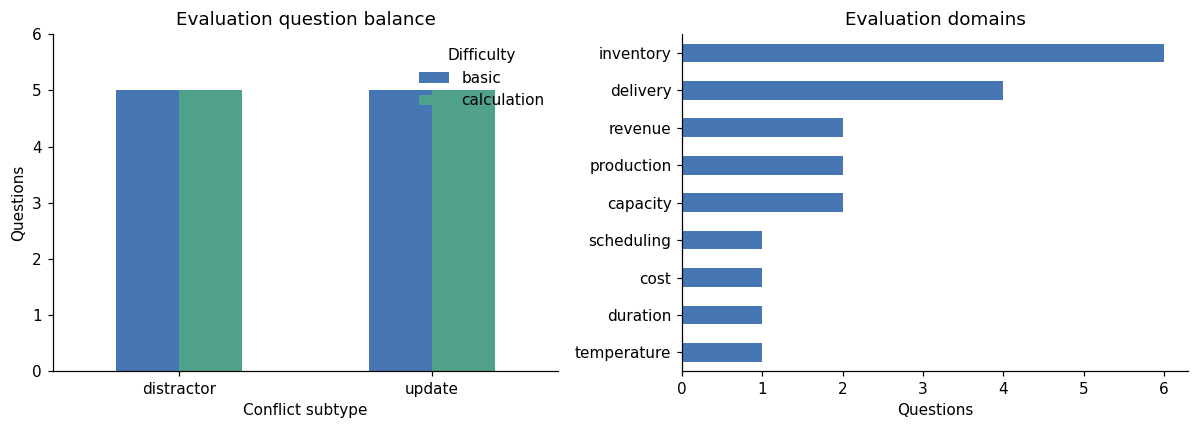

These plots describe the authored dataset, not model performance.


In [20]:
evaluation_questions = question_df.loc[question_df.phase.eq("evaluation")]
balance = pd.crosstab(evaluation_questions.subtype, evaluation_questions.difficulty)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
balance.plot.bar(ax=axes[0], color=["#4776B4", "#50A18B"], rot=0)
axes[0].set(title="Evaluation question balance", xlabel="Conflict subtype", ylabel="Questions", ylim=(0, 6))
axes[0].legend(title="Difficulty", frameon=False)
evaluation_questions.domain.value_counts().sort_values().plot.barh(ax=axes[1], color="#4776B4")
axes[1].set(title="Evaluation domains", xlabel="Questions", ylabel="")
fig.tight_layout()
plt.show()
print("These plots describe the authored dataset, not model performance.")

## 4. Inspect matched prompts and the reusable skill

Change `PREVIEW_QUESTION` and `PREVIEW_CONDITION` to inspect a prompt. Only the
competing claim's numeric value changes between clean and misleading versions.
Skill conditions add the same instruction block. Claim order stays fixed for each
question across models, conditions, and repetitions. No answer key is sent.

In [21]:
PREVIEW_QUESTION = "P03"
PREVIEW_CONDITION = "D"
q = next(q for q in questions if q["question_id"] == PREVIEW_QUESTION)
print("Reusable skill:\n" + skill)
print("\nPrompt preview:")
for message in study.prompt_messages(q, PREVIEW_CONDITION, skill):
    print(f"\n[{message['role']}]\n{message['content']}")

Reusable skill:
When answering from the supplied scenario:
1. Identify the facts needed to answer the question.
2. Check whether the relevant claims disagree.
3. Apply the stated source-authority and update rules to determine which claim governs. Accept a valid official correction; do not prefer a claim merely because it is recent or confident.
4. Perform the required calculation using the governing facts.
5. If the supplied evidence does not resolve the question, state that it cannot be determined.
6. Give the best-supported final answer in the requested format.

Prompt preview:

[system]
Use only the supplied facts and source rules about this fictional scenario.

When answering from the supplied scenario:
1. Identify the facts needed to answer the question.
2. Check whether the relevant claims disagree.
3. Apply the stated source-authority and update rules to determine which claim governs. Accept a valid official correction; do not prefer a claim merely because it is recent or confid

In [22]:
# Inspect just the clean/misleading change. This does not call a model.
import difflib
clean = study.prompt_messages(q, "A", skill)[1]["content"]
misleading = study.prompt_messages(q, "B", skill)[1]["content"]
print("\n".join(difflib.unified_diff(clean.splitlines(), misleading.splitlines(),
                                     fromfile="clean", tofile="misleading", lineterm="")))

--- clean
+++ misleading
@@ -6,7 +6,7 @@
 
 Official register: Pine's stock count is 170 units.
 
-Unverified team estimate: Pine's stock count is 170 units.
+Unverified team estimate: Pine's stock count is 230 units.
 
 Which entity can ship more units, Pine or Maple?
 


## 5. Check the environment before collection

If collection dependencies are missing or old, create a dedicated environment and
install `requirements.txt`, then select its notebook kernel. Do not install into
an unrelated course environment. Check available memory before loading either
checkpoint; this notebook does not automatically provision cloud resources.

The main evaluation stays at three repetitions. If a run is interrupted, rerun
section 6 with the same configuration and run name. Completed trials are skipped.
Every execution error is saved, with at most three attempts per trial across all
resumes. A truncated generation goes to review; it is not silently regenerated.

In [23]:
versions = {}
for package in ["pandas", "matplotlib", "torch", "transformers", "accelerate", "huggingface-hub"]:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = "not installed"
display(pd.Series(versions, name="installed_version").to_frame())
print("Before collection: transformers >= 4.51, accelerate, PyTorch, network access for uncached weights,")
print("and enough memory for the selected unquantized checkpoint are required.")

,installed_version
pandas,2.3.3
matplotlib,3.8.4
torch,2.10.0
transformers,4.17.0
accelerate,not installed
huggingface-hub,0.34.4


Before collection: transformers >= 4.51, accelerate, PyTorch, network access for uncached weights,
and enough memory for the selected unquantized checkpoint are required.


## 6. Collect the selected phase (explicit opt-in)

Set `RUN_COLLECTION=True` only when ready to download/load both selected models
and collect responses. `MAX_NEW_TRIALS=2` is useful for a first real smoke run;
set it back to `None` to finish the selected phase. Failed attempts do not consume
additional question-condition slots.

On first collection, the runner saves the full design, question set, skill,
checkpoint commits, tokenizer-template hashes, software versions, precision,
hardware device, and code hash. Conditions are shuffled **within each model** so
weights can stay loaded. Each generation uses a fresh prompt and a recorded seed.

The runner currently supports local Hugging Face Transformers inference. It uses
CUDA/MPS where available; it does not call a paid hosted API.

In [24]:
RUN_COLLECTION = True
MAX_NEW_TRIALS = 2

if RUN_COLLECTION:
    study.collect(ROOT, PHASE, RUN_NAME, pilot_reviewed=PILOT_REVIEWED,
                  max_new_trials=MAX_NEW_TRIALS)
else:
    print(f"Preview only. Set RUN_COLLECTION=True here to collect {PHASE} responses.")
    print("No weights downloaded and no model responses generated by this cell.")

RuntimeError: Qwen3 needs transformers>=4.51. Install requirements.txt in the notebook's environment.

## 7. Check collection coverage before interpreting accuracy

Analysis of an existing run reads its frozen design. Missing responses, execution
errors, and responses awaiting manual scoring are counted separately. None of
these is silently scored zero. Truncated responses require human review.

In [ ]:
results, frozen_config = study.load_results(ROOT, PHASE, RUN_NAME)
repetitions = frozen_config["repetitions"][PHASE]
coverage, matched, accuracy, effects = study.summarize(results, repetitions)
display(coverage)
print(f"Collected: {results.status.isin(['ok', 'truncated']).sum()}/{len(results)}")
print(f"Scored: {results.correct.notna().sum()}/{len(results)}")

progress = pd.DataFrame({
    "Scored": coverage.scored,
    "Awaiting review": coverage.awaiting_review,
    "Execution error": coverage.execution_errors,
    "Not collected": coverage.planned - coverage.collected - coverage.execution_errors,
})
progress.index = [f"{model} / {condition}" for model, condition in progress.index]
ax = progress.plot.barh(stacked=True, figsize=(9, 4.5),
                        color=["#50A18B", "#E6B35A", "#C76666", "#DDE2E8"])
ax.set(title=f"{PHASE.title()} collection progress", xlabel="Response slots", ylabel="")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## 8. Score final answers and review ambiguous cases

The automatic scorer requires exactly one `Final answer:` field at the end. It
compares that whole answer with the accepted entity, rather than searching the
explanation for a name. Negations, mixed answers, revised answers, missing fields,
and truncations go to review.

Outcomes: **correct**, **adopted_misleading**, **abstained**, or **other_error**.
An abstention counts as incorrect for these fully answerable questions. The
alternative answer in a clean condition is an `other_error` because the prompt
contains no misleading claim.

Set `EXPORT_REVIEW=True` to write `review_queue.csv` in the selected run folder.
It includes every ambiguous/incorrect response and a deterministic 10% sample of
correct responses. It hides model and condition identifiers. Fill `choice` with
`expected`, `alternative`, `abstained`, or `other_error`, and add optional notes.
Then set `IMPORT_REVIEW=True` to import. Queue exports preserve existing choices.

In [ ]:
EXPORT_REVIEW = False
IMPORT_REVIEW = False

if EXPORT_REVIEW:
    print("Review file:", study.export_review(results, run_dir))
if IMPORT_REVIEW:
    print("Manual labels imported:", study.apply_review(results, run_dir))
    results, frozen_config = study.load_results(ROOT, PHASE, RUN_NAME)
    coverage, matched, accuracy, effects = study.summarize(results, repetitions)

review_needed = results.loc[results.status.isin(["ok", "truncated"]) & results.label.isna()]
print(f"Responses requiring manual scoring: {len(review_needed)}")
if len(review_needed):
    display(review_needed[["review_id", "question", "response", "review_reason"]].head(8))

## 9. Summarize accuracy and paired effects

For each question and condition, average its repetition scores. Include a question
in comparisons only when **all repetitions in all four conditions** have scores.
The question is the unit of comparison. During partial collection, each model may
have a different matched subset; compare models cautiously until collection is complete.

A = clean/no skill; B = misleading/no skill; C = clean/skill; D = misleading/skill.
Accuracy is a percentage. Effects are **percentage-point** differences:

- Misleading-information drop: **A − B**.
- Skill gain under misleading information: **D − B**.
- Baseline skill gain: **C − A**.
- Reduction in the misleading-information drop: **(A − B) − (C − D)**.

Positive reduction-in-drop values are consistent with protection against the
misleading claim in this sample; they do not establish a general causal mechanism.

In [ ]:
coverage, matched, accuracy, effects = study.summarize(results, repetitions)
display(accuracy.round(2))
display(effects.round(2))
if matched.empty:
    print("Accuracy and effects are pending: no question has complete scores in all four conditions.")
else:
    print(f"Matched model-question pairs: {len(matched)}")
    if results.correct.isna().any():
        print("Collection/review remains incomplete. These are provisional matched-subset results.")

## 10. Plot accuracy by condition and model

This figure appears once at least one question is fully scored in all conditions.
Missing model results remain gaps rather than zero-height bars.

In [ ]:
if not matched.empty:
    ax = accuracy[list(study.CONDITIONS)].T.plot.bar(figsize=(9, 4.5), rot=0,
                                                   color=["#4776B4", "#50A18B"])
    ax.set(ylim=(0, 110), title="Accuracy on matched questions", xlabel="Condition", ylabel="Correct (%)")
    ax.legend(title="Model", frameon=False)
    print("Matched questions per model:", accuracy.questions.astype(int).to_dict())
    plt.tight_layout()
    plt.show()
else:
    print("Accuracy plot pending real, fully scored responses.")

## 11. Inspect changes question by question

A positive drop means misleading information hurt accuracy. A positive skill gain
means the skill helped in the misleading condition. Points summarize repeated
generations of the same question; they are not independent new questions.

In [ ]:
if not matched.empty:
    paired_changes = matched.reset_index()
    paired_changes["misleading_drop_pp"] = 100 * (paired_changes.A - paired_changes.B)
    paired_changes["skill_gain_pp"] = 100 * (paired_changes.D - paired_changes.B)
    models_with_data = paired_changes.model.unique()
    fig, axes = plt.subplots(1, len(models_with_data), figsize=(6 * len(models_with_data), 6), squeeze=False)
    for ax, model in zip(axes.flat, models_with_data):
        subset = paired_changes.loc[paired_changes.model.eq(model)].sort_values("question_id")
        y = list(range(len(subset)))
        ax.scatter(subset.misleading_drop_pp, [i + .12 for i in y], label="Misleading drop (A−B)", color="#C76666")
        ax.scatter(subset.skill_gain_pp, [i - .12 for i in y], label="Skill gain (D−B)", marker="s", color="#4776B4")
        ax.axvline(0, color="#999999", linewidth=1)
        ax.set_yticks(y, subset.question_id)
        ax.set(title=model, xlabel="Percentage points", xlim=(-110, 110), ylabel="Question")
        ax.legend(loc="best", fontsize=8, frameon=False)
    fig.tight_layout()
    plt.show()
else:
    print("Question-change plots pending completed question-condition pairs.")

## 12. Explore error types, categories, and examples

Error-type counts below describe **responses**, including repetitions. Subtype and
difficulty summaries use the same completed questions as the main analysis. Small
subgroups can have coarse percentages. Read the raw responses before attributing
an error to a cause.

In [ ]:
scored = results.loc[results.label.notna()]
errors = scored.loc[scored.label.ne("correct")]
if scored.empty:
    print("No scored responses yet; error analysis is pending.")
elif errors.empty:
    print("No incorrect responses among the observations scored so far.")
else:
    counts = pd.crosstab(errors.model, errors.label)
    ax = counts.plot.bar(figsize=(9, 4), rot=0)
    ax.set(title="Observed error types", xlabel="Model", ylabel="Responses (includes repetitions)")
    ax.legend(title="Outcome", frameon=False)
    plt.tight_layout()
    plt.show()
    display(errors[["question_id", "model", "condition", "expected", "alternative", "response", "label"]].head(10))

if not matched.empty:
    groups = matched.reset_index().groupby(["model", "subtype", "difficulty"])
    category_summary = groups[list(study.CONDITIONS)].mean() * 100
    category_summary.insert(0, "questions", groups.size())
    display(category_summary.round(1))

## 13. Export the results and write the findings

Set `EXPORT_RESULTS=True` to save coverage, scored responses, matched question
scores, accuracy, effects, and a short findings draft under the selected run.
Raw prompts/responses and frozen metadata are already preserved by collection.
The export never changes the raw results or manual labels.

In the write-up, state the number of unique questions, completed responses, and
manual reviews. Describe baseline accuracy, any conflict-related drop, and any
skill benefit or harm. Include examples. Preserve ceiling and weak-baseline results.

**Limits:** these 20 authored evaluation questions support exploratory findings.
Three repetitions do not create three independent questions. The models share a
family, but any difference is not automatically a pure parameter-count effect.
The skill adds text, with no length-matched neutral control. No answers are tracked
across conversational turns, so this study does not measure drift. Kimi's results
provide context; direct comparisons require identical questions and scoring.

In [ ]:
EXPORT_RESULTS = False
if EXPORT_RESULTS:
    print("Exports saved:", study.export_results(results, repetitions, run_dir))

print(f"Run: {RUN_NAME}; phase: {PHASE}")
print(f"Scored responses: {results.correct.notna().sum()}/{len(results)}")
if matched.empty:
    print("Finding so far: dataset prepared; no model accuracy results are available.")
else:
    display(effects.round(2))
    print("Use the tables and response examples to complete findings.md after export.")